# 01 — Exploração da base para o modelo de atraso

**Objetivo:** entender o volume de dados disponível antes de treinar o modelo.

1. Total de pedidos e seus status
2. Quantos foram entregues e quantos atrasaram
3. Unidade de previsão: o **envio** (pedido + vendedor)
4. Quantos envios são **elegíveis** para o treinamento
5. Evolução mensal: volume e taxa de atraso
6. Prévia da divisão temporal entre treino e teste

> **Regra de atraso** (a mesma do backend): entregue depois do **dia** estimado.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Raiz do projeto: a primeira pasta (atual ou acima) que contém "backend"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())
RAW = ROOT / "backend" / "data" / "raw"

pd.set_option("display.float_format", "{:,.2f}".format)
COLOR = "#2a78d6"
print(RAW)

c:\Users\carlo\Documents\Meus arquivos\Faculdade\5-semestre\HypoLog\backend\data\raw


## Carregar os CSVs da Olist

In [4]:
date_cols = ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]

orders = pd.read_csv(RAW / "olist_orders_dataset.csv", parse_dates=date_cols)
items = pd.read_csv(RAW / "olist_order_items_dataset.csv")
products = pd.read_csv(RAW / "olist_products_dataset.csv")
customers = pd.read_csv(RAW / "olist_customers_dataset.csv")
sellers = pd.read_csv(RAW / "olist_sellers_dataset.csv")
geo = pd.read_csv(RAW / "olist_geolocation_dataset.csv")

for name, df in [("orders", orders), ("items", items), ("products", products),
                 ("customers", customers), ("sellers", sellers), ("geolocation", geo)]:
    print(f"{name:<12} {len(df):>10,} linhas")

orders           99,441 linhas
items           112,650 linhas
products         32,951 linhas
customers        99,441 linhas
sellers           3,095 linhas
geolocation   1,000,163 linhas


## Bloco 1 — Total de pedidos por status

In [5]:
status = orders["order_status"].value_counts().rename("pedidos").to_frame()
status["%"] = status["pedidos"] / status["pedidos"].sum() * 100

print(f"Total de pedidos: {len(orders):,}")
status

Total de pedidos: 99,441


,pedidos,%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


## Bloco 2 — Entregues e atrasados

Só servem para treinar os pedidos **entregues e com data de entrega**: sem a data, não dá para saber se atrasou.

In [6]:
delivered = orders[
    (orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].notna()
].copy()

delay_days = (
    delivered["order_delivered_customer_date"].dt.normalize()
    - delivered["order_estimated_delivery_date"].dt.normalize()
).dt.days
delivered["is_delayed"] = delay_days > 0

total = len(delivered)
delayed = int(delivered["is_delayed"].sum())
print(f"Entregues com data:  {total:,}")
print(f"Atrasados:           {delayed:,}")
print(f"No prazo:            {total - delayed:,}")
print(f"Taxa de atraso:      {delayed / total:.2%}")

Entregues com data:  96,470
Atrasados:           6,534
No prazo:            89,936
Taxa de atraso:      6.77%


## Bloco 3 — Unidade de previsão: o envio

Um pedido pode ter itens de vendedores diferentes, e cada vendedor despacha do seu endereço.
Por isso o modelo prevê o atraso de cada **envio** (pedido + vendedor), e não do pedido inteiro.

In [7]:
sellers_per_order = items.groupby("order_id")["seller_id"].nunique()
multi = sellers_per_order[sellers_per_order > 1]

shipments = (
    items.merge(products, on="product_id", how="left")
    .assign(volume_cm3=lambda d: d["product_length_cm"] * d["product_height_cm"] * d["product_width_cm"])
    .groupby(["order_id", "seller_id"], as_index=False)
    .agg(
        n_items=("order_item_id", "size"),
        weight_g=("product_weight_g", lambda s: s.sum(min_count=len(s))),  # NaN se faltar algum produto
        volume_cm3=("volume_cm3", lambda s: s.sum(min_count=len(s))),
    )
)
shipments = shipments.merge(delivered, on="order_id")

print(f"Pedidos com mais de 1 vendedor: {len(multi):,} ({len(multi) / items['order_id'].nunique():.2%})")
print(f"Envios de pedidos entregues:    {len(shipments):,}")

Pedidos com mais de 1 vendedor: 1,278 (1.30%)
Envios de pedidos entregues:    97,811


## Bloco 4 — Envios elegíveis para o treinamento

Um envio só entra no treino se tiver tudo o que o modelo usa:

| Critério | Por quê |
|---|---|
| Coordenadas de origem e destino | Necessárias para calcular a distância |
| Peso e dimensões de todos os produtos | Features de peso e volume |
| Prazo prometido maior que zero | Data estimada depois da compra |

In [8]:
coords = set(geo["geolocation_zip_code_prefix"].unique())

df = (
    shipments.merge(customers[["customer_id", "customer_zip_code_prefix"]], on="customer_id")
    .merge(sellers[["seller_id", "seller_zip_code_prefix"]], on="seller_id")
)
df["promised_days"] = (
    df["order_estimated_delivery_date"].dt.normalize() - df["order_purchase_timestamp"].dt.normalize()
).dt.days

criteria = [
    ("Coordenadas do destino", df["customer_zip_code_prefix"].isin(coords)),
    ("Coordenadas da origem", df["seller_zip_code_prefix"].isin(coords)),
    ("Peso e dimensões dos produtos", df["weight_g"].notna() & df["volume_cm3"].notna()),
    ("Prazo prometido > 0", df["promised_days"] > 0),
]

funnel = [("Envios entregues", len(df), None)]
keep = pd.Series(True, index=df.index)
for label, rule in criteria:
    before = keep.sum()
    keep &= rule
    funnel.append((label, int(keep.sum()), int(before - keep.sum())))

funnel = pd.DataFrame(funnel, columns=["etapa", "restantes", "removidos"]).astype({"removidos": "Int64"})
eligible = df[keep].copy()

print(f"Elegíveis: {len(eligible):,} de {len(df):,} envios ({len(eligible) / len(df):.2%})")
print(f"Taxa de atraso nos elegíveis: {eligible['is_delayed'].mean():.2%}")
funnel

Elegíveis: 97,309 de 97,811 envios (99.49%)
Taxa de atraso nos elegíveis: 6.68%


,etapa,restantes,removidos
0,Envios entregues,97811,<NA>
1,Coordenadas do destino,97541,270
2,Coordenadas da origem,97325,216
3,Peso e dimensões dos produtos,97309,16
4,Prazo prometido > 0,97309,0


## Bloco 5 — Evolução mensal

Dois gráficos separados (volume e taxa) para não misturar escalas diferentes no mesmo eixo.

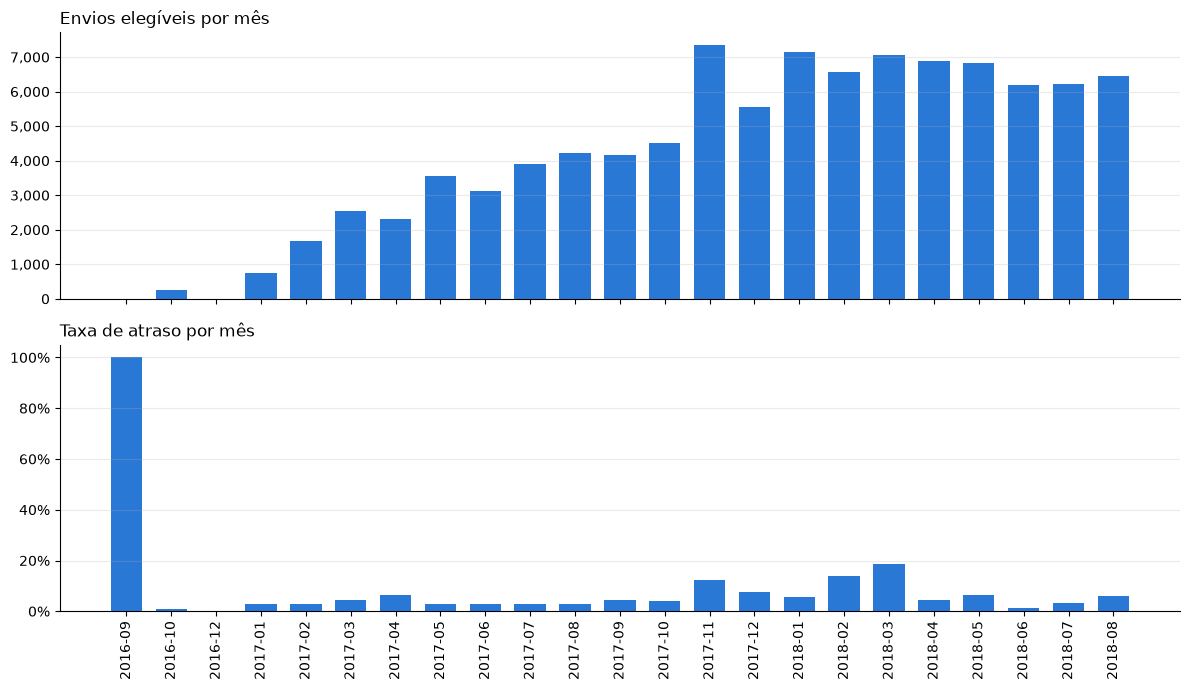

,shipments,delay_rate
month,,
2016-09,1,1.00
2016-10,268,0.01
2016-12,1,0.00
2017-01,753,0.03
2017-02,1666,0.03
2017-03,2538,0.05
2017-04,2301,0.06
2017-05,3558,0.03
2017-06,3136,0.03


In [9]:
monthly = (
    eligible.assign(month=eligible["order_purchase_timestamp"].dt.to_period("M"))
    .groupby("month")
    .agg(shipments=("order_id", "size"), delay_rate=("is_delayed", "mean"))
)
labels = monthly.index.astype(str)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, col, title, fmt in [
    (axes[0], "shipments", "Envios elegíveis por mês", "{:,.0f}"),
    (axes[1], "delay_rate", "Taxa de atraso por mês", "{:.0%}"),
]:
    ax.bar(labels, monthly[col], color=COLOR, width=0.7)
    ax.set_title(title, loc="left", fontsize=12)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, f=fmt: f.format(v)))
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

monthly

## Bloco 6 — Prévia da divisão temporal

O modelo treina com os envios **mais antigos** e é testado com os **mais recentes**, simulando o uso real.
Meses com volume muito baixo (início e fim da base) ficam de fora.

In [10]:
START, SPLIT, END = "2017-01-01", "2018-04-01", "2018-09-01"

purchase = eligible["order_purchase_timestamp"]
window = eligible[(purchase >= START) & (purchase < END)]
train = window[window["order_purchase_timestamp"] < SPLIT]
test = window[window["order_purchase_timestamp"] >= SPLIT]

split = pd.DataFrame({
    "período": [f"{START} a {SPLIT}", f"{SPLIT} a {END}"],
    "envios": [len(train), len(test)],
    "% do total": [len(train) / len(window) * 100, len(test) / len(window) * 100],
    "atrasados": [int(train["is_delayed"].sum()), int(test["is_delayed"].sum())],
    "taxa de atraso %": [train["is_delayed"].mean() * 100, test["is_delayed"].mean() * 100],
}, index=["treino", "teste"])

print(f"Fora da janela: {len(eligible) - len(window):,} envios")
split

Fora da janela: 270 envios


,período,envios,% do total,atrasados,taxa de atraso %
treino,2017-01-01 a 2018-04-01,64458,66.42,5089,7.90
teste,2018-04-01 a 2018-09-01,32581,33.58,1411,4.33


## Conclusões

- **Total de pedidos:** 99.441 (97,02% com status `delivered`)
- **Entregues com data / atrasados / taxa:** 96.470 / 6.534 / 6,77%
- **Envios (pedido + vendedor):** 97.811. Só 1,30% dos pedidos têm mais de um vendedor
- **Envios elegíveis:** 97.309 (99,49%). As perdas vêm quase todas de CEPs sem coordenada
  (270 no destino e 216 na origem) e de 16 envios sem peso ou dimensões
- **Divisão treino / teste:** 64.458 (66,4%) / 32.581 (33,6%). Ficam de fora 270 envios
  de set–dez/2016, meses com volume quase nulo
- **Taxa de atraso no treino / teste:** 7,90% / 4,33%

### Observações
- A taxa de atraso **não é estável ao longo do tempo**. Há picos em nov/2017 (12%,
  mês da Black Friday), fev/2018 (14%) e mar/2018 (19%). Os demais meses ficam entre 1% e 6%.
- Os três picos caem no período de **treino**, por isso o treino tem quase o dobro da
  taxa de atraso do teste.
- **Consequência:** o modelo aprende com um período mais "turbulento" do que aquele em
  que é avaliado. A Precision no teste tende a ser menor, porque o modelo vai prever mais
  atrasos do que realmente acontecem. Isso precisa entrar na análise das métricas.